# SkyCity Auckland Restaurants & Bars: Channel Profitability
**Question:** which channel (In-Store, Uber Eats, DoorDash, Self-Delivery) really makes money?
Steps: 1) load and check data, 2) validate profit formulas, 3) compare channels, 4) cost breakdown, 5) what-if tests, 6) cuisine/segment, 7) risk, 8) conclusions.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

df = pd.read_csv("SkyCity_Auckland_Restaurants___Bars.csv")
print(df.shape, "| missing values:", df.isna().sum().sum(), "| duplicate IDs:", df.RestaurantID.duplicated().sum())
df.head()

(1696, 30) | missing values: 0 | duplicate IDs: 0


,CuisineType,RestaurantID,RestaurantName,Segment,Subregion,GrowthFactor,AOV,MonthlyOrders,InStoreOrders,InStoreRevenue,...,DeliveryCostPerOrder,SD_DeliveryTotalCost,InStoreNetProfit,UberEatsNetProfit,DoorDashNetProfit,SelfDeliveryNetProfit,InStoreShare,UE_share,DD_share,SD_share
0,Burgers,25731,Urban Burgers House,Cafe,North Shore,1.03,43.97,668,197,"8,662.09",...,3.25,458.25,"3,682.14","1,352.45",752.78,"2,177.19",0.42,0.45,0.25,0.30
1,Burgers,25123,Urban Burgers Diner,QSR,South Auckland,1.05,40.45,1388,259,"10,476.55",...,4.72,"1,600.08","3,605.72","1,318.61",731.99,"3,119.38",0.23,0.45,0.25,0.30
2,Burgers,25177,King Burgers Eatery,Cafe,West Auckland,1.04,40.03,1717,524,"20,975.72",...,3.25,"1,163.50","7,810.95","1,555.90",863.42,"4,172.99",0.44,0.45,0.25,0.30
3,Burgers,25540,Classic Burgers Tavern,QSR,North Shore,1.03,36.28,1083,216,"7,836.48",...,0.89,231.40,"2,546.02",-72.25,-40.20,"2,833.26",0.25,0.45,0.25,0.30
4,Burgers,25258,Lucky Burgers Bistro,Cafe,South Auckland,1.05,34.34,1230,261,"8,962.74",...,2.66,774.06,"3,093.09",226.17,125.53,"2,674.56",0.27,0.45,0.25,0.30


## 1. Quick data check

In [2]:
df.describe().T[["min","mean","max"]]

,min,mean,max
RestaurantID,"25,001.00","25,848.50","26,696.00"
GrowthFactor,0.99,1.03,1.05
AOV,29.79,38.52,47.23
MonthlyOrders,441.00,"1,190.53","2,337.00"
InStoreOrders,13.00,218.98,819.00
InStoreRevenue,412.36,"8,422.39","35,356.23"
UberEatsOrders,142.00,471.91,937.00
DoorDashOrders,81.00,257.16,466.00
SelfDeliveryOrders,60.00,242.49,702.00
UberEatsRevenue,"5,050.95","18,170.03","43,038.96"


## 2. Validate the profit formulas
We rebuild each net profit from revenue, COGS, OPEX, commission and delivery cost and compare with the file. A difference under $0.01 is just rounding.

In [3]:
base = 1 - df.COGSRate - df.OPEXRate          # margin before commission / delivery
check = pd.DataFrame({
    "In-Store":      df.InStoreRevenue*base - df.InStoreNetProfit,
    "Uber Eats":     df.UberEatsRevenue*(base-df.CommissionRate) - df.UberEatsNetProfit,
    "DoorDash":      df.DoorDashRevenue*(base-df.CommissionRate) - df.DoorDashNetProfit,
    "Self-Delivery": df.SelfDeliveryRevenue*base - df.SD_DeliveryTotalCost - df.SelfDeliveryNetProfit,
})
print("Largest formula difference ($):")
print(check.abs().max())
print("Orders add up:", (df[["InStoreOrders","UberEatsOrders","DoorDashOrders","SelfDeliveryOrders"]].sum(axis=1)==df.MonthlyOrders).all())
print("Delivery cost = orders x cost per order:", np.allclose(df.SelfDeliveryOrders*df.DeliveryCostPerOrder, df.SD_DeliveryTotalCost))

Largest formula difference ($):
In-Store        0.00
Uber Eats       0.00
DoorDash        0.00
Self-Delivery   0.00
dtype: float64
Orders add up: True
Delivery cost = orders x cost per order: True


All formulas in the dataset are correct, so we can trust the profit columns.

## 3. Build one tidy table (restaurant x channel)

In [4]:
def build(df, comm_shift=0.0, cost_shift=0.0):
    comm = (df.CommissionRate + comm_shift).clip(lower=0)
    cost = (df.DeliveryCostPerOrder + cost_shift).clip(lower=0)
    parts = []
    for ch, o, r in [("In-Store","InStoreOrders","InStoreRevenue"),("Uber Eats","UberEatsOrders","UberEatsRevenue"),
                     ("DoorDash","DoorDashOrders","DoorDashRevenue"),("Self-Delivery","SelfDeliveryOrders","SelfDeliveryRevenue")]:
        t = df[["RestaurantID","CuisineType","Segment","Subregion"]].copy()
        t["Channel"] = ch
        t["Orders"], t["Revenue"] = df[o], df[r]
        t["COGS"], t["OPEX"] = t.Revenue*df.COGSRate, t.Revenue*df.OPEXRate
        t["Commission"] = t.Revenue*comm if "Uber" in ch or "Door" in ch else 0.0
        t["Delivery"] = t.Orders*cost if ch == "Self-Delivery" else 0.0
        t["Profit"] = t.Revenue - t.COGS - t.OPEX - t.Commission - t.Delivery
        t["Margin %"] = t.Profit/t.Revenue*100
        t["Profit/Order"] = t.Profit/t.Orders
        parts.append(t)
    return pd.concat(parts, ignore_index=True)

def summary(t, by="Channel"):
    g = t.groupby(by)[["Orders","Revenue","COGS","OPEX","Commission","Delivery","Profit"]].sum()
    g["Margin %"] = g.Profit/g.Revenue*100
    g["Profit/Order"] = g.Profit/g.Orders
    g["Commission Drag %"] = np.where(g.Commission>0, g.Commission/(g.Profit+g.Commission)*100, 0)
    return g

long = build(df)
order = ["In-Store","Uber Eats","DoorDash","Self-Delivery"]
S = summary(long).loc[order]
S

,Orders,Revenue,COGS,OPEX,Commission,Delivery,Profit,Margin %,Profit/Order,Commission Drag %
Channel,,,,,,,,,,
In-Store,371391,"14,284,378.07","4,226,913.99","6,229,046.81",0.00,0.00,"3,828,417.27",26.80,10.31,0.00
Uber Eats,800353,"30,816,371.49","8,631,091.83","12,672,810.32","9,253,981.25",0.00,"258,488.10",0.84,0.32,97.28
DoorDash,436135,"16,789,380.95","4,699,249.47","6,898,068.59","5,040,940.77",0.00,"151,122.12",0.90,0.35,97.09
Self-Delivery,411255,"15,849,176.29","4,428,545.49","6,510,542.83",0.00,"1,281,809.47","3,628,278.50",22.89,8.82,0.00


## 4. Channel comparison: volume vs profit

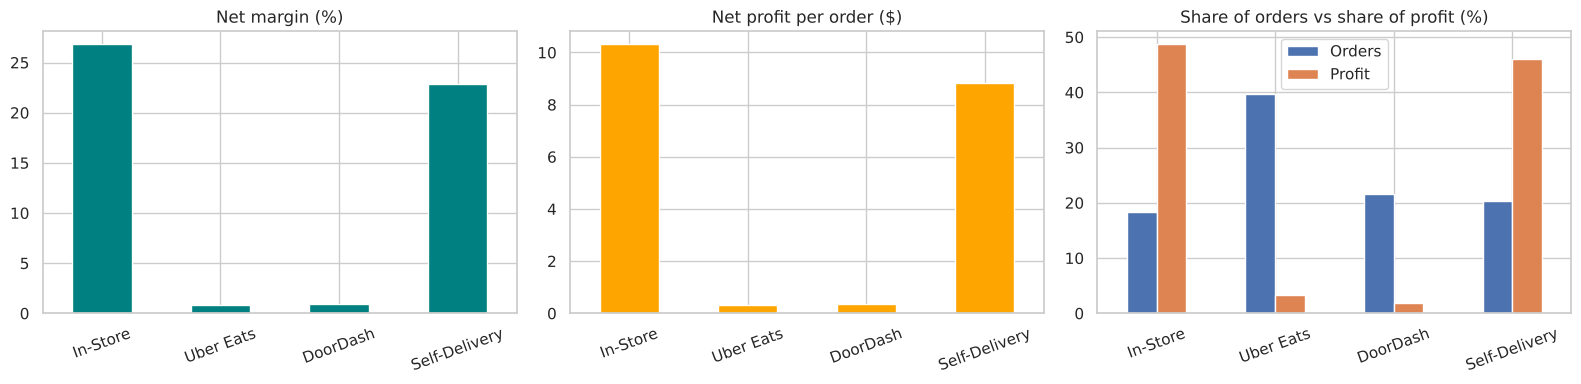

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
S["Margin %"].plot.bar(ax=ax[0], color="teal", title="Net margin (%)")
S["Profit/Order"].plot.bar(ax=ax[1], color="orange", title="Net profit per order ($)")
(S[["Orders","Profit"]]/S[["Orders","Profit"]].sum()*100).plot.bar(ax=ax[2], title="Share of orders vs share of profit (%)")
for a in ax: a.set_xlabel(""); a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

**Finding:** Uber Eats and DoorDash bring about 61% of all orders, but almost no profit. In-Store earns the best margin, and Self-Delivery is a close second.

## 5. Cost breakdown and margin waterfall

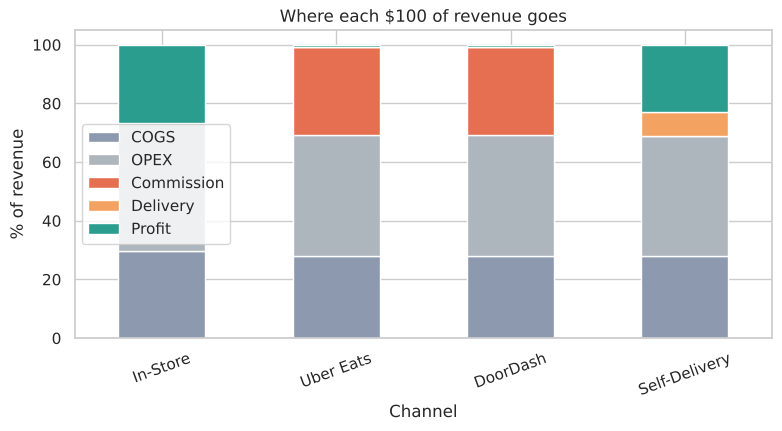

,COGS,OPEX,Commission,Delivery,Profit
Channel,,,,,
In-Store,29.60,43.60,0.00,0.00,26.80
Uber Eats,28.00,41.10,30.00,0.00,0.80
DoorDash,28.00,41.10,30.00,0.00,0.90
Self-Delivery,27.90,41.10,0.00,8.10,22.90


In [6]:
pct = S[["COGS","OPEX","Commission","Delivery","Profit"]].div(S.Revenue, axis=0)*100
pct.plot.bar(stacked=True, figsize=(9,4), color=["#8d99ae","#adb5bd","#e76f51","#f4a261","#2a9d8f"])
plt.ylabel("% of revenue"); plt.title("Where each $100 of revenue goes"); plt.xticks(rotation=20); plt.show()
pct.round(1)

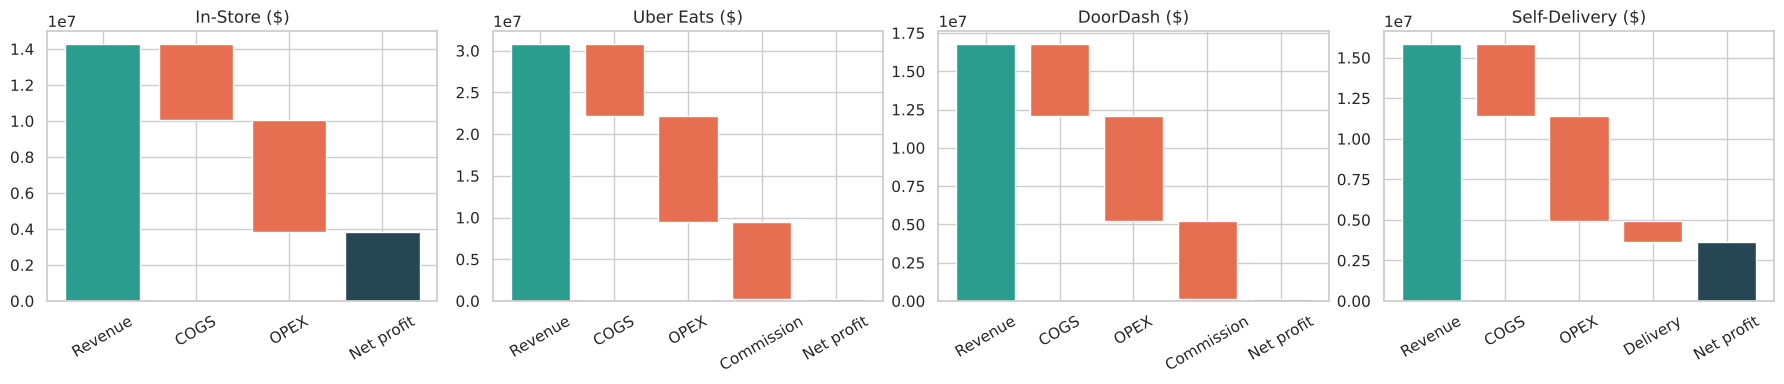

In [7]:
def waterfall(ch, ax):
    r = S.loc[ch]
    items = [("Revenue", r.Revenue), ("COGS", -r.COGS), ("OPEX", -r.OPEX)]
    if r.Commission: items.append(("Commission", -r.Commission))
    if r.Delivery:   items.append(("Delivery", -r.Delivery))
    run = 0
    for label, v in items:
        ax.bar(label, abs(v), bottom=run if v > 0 else run + v, color="#2a9d8f" if v > 0 else "#e76f51")
        run += v
    ax.bar("Net profit", run, color="#264653")
    ax.set_title(f"{ch} ($)"); ax.tick_params(axis="x", rotation=30)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ch, ax in zip(order, axes): waterfall(ch, ax)
plt.tight_layout(); plt.show()

**Commission Drag Index** = commission ÷ profit before commission. **Self-Delivery ROI** = net profit ÷ delivery cost.

In [8]:
print(S.loc[["Uber Eats","DoorDash"], "Commission Drag %"].round(1))
print("Self-delivery ROI: $%.2f profit per $1 of delivery cost" % (S.loc["Self-Delivery","Profit"]/S.loc["Self-Delivery","Delivery"]))

Channel
Uber Eats   97.30
DoorDash    97.10
Name: Commission Drag %, dtype: float64
Self-delivery ROI: $2.83 profit per $1 of delivery cost


## 6. What-if: commission and delivery cost
**Breakeven logic**
- An aggregator order loses money when `CommissionRate > 1 - COGS - OPEX`.
- Self-delivery beats an aggregator while `cost per order < AOV x CommissionRate`.

In [9]:
d = df.assign(pre_margin = 1-df.COGSRate-df.OPEXRate, be_cost = df.AOV*df.CommissionRate)
print("Avg margin before commission: %.1f%%" % (d.pre_margin.mean()*100))
print("Restaurants losing money on aggregators: %.0f%%" % ((d.CommissionRate>d.pre_margin).mean()*100))
print("Self-delivery breakeven cost vs aggregator: $%.2f per order (actual average $%.2f, max $%.2f)" %
      (d.be_cost.mean(), d.DeliveryCostPerOrder.mean(), d.DeliveryCostPerOrder.max()))

Avg margin before commission: 30.8%
Restaurants losing money on aggregators: 32%
Self-delivery breakeven cost vs aggregator: $11.56 per order (actual average $3.12, max $5.31)


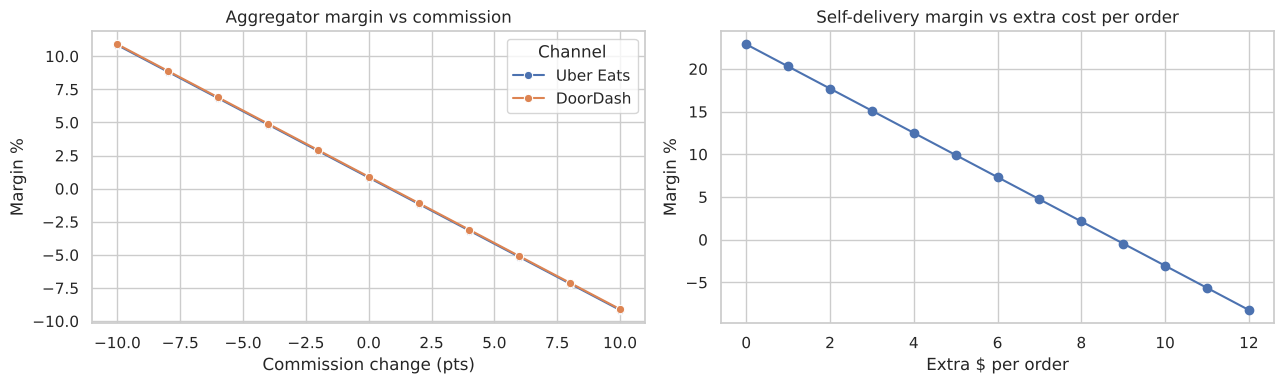

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13,4))
pts = [(p, summary(build(df, p/100)).loc[c, "Margin %"], c) for p in range(-10,11,2) for c in ["Uber Eats","DoorDash"]]
sns.lineplot(data=pd.DataFrame(pts, columns=["Commission change (pts)","Margin %","Channel"]),
             x="Commission change (pts)", y="Margin %", hue="Channel", marker="o", ax=ax[0]); ax[0].set_title("Aggregator margin vs commission")
pts = [(x, summary(build(df, 0, x)).loc["Self-Delivery","Margin %"]) for x in range(0,13)]
ax[1].plot(*zip(*pts), marker="o"); ax[1].set_title("Self-delivery margin vs extra cost per order"); ax[1].set_xlabel("Extra $ per order"); ax[1].set_ylabel("Margin %")
plt.tight_layout(); plt.show()

## 7. Cuisine and segment comparison

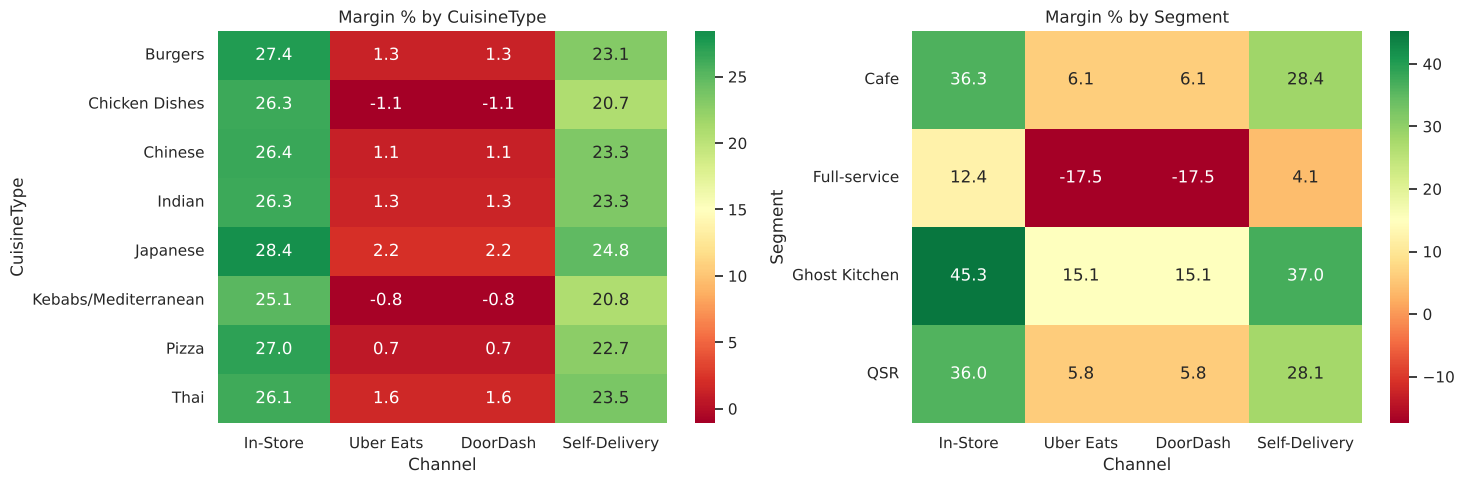

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15,5))
for a, dim in zip(ax, ["CuisineType","Segment"]):
    h = summary(long, [dim,"Channel"])["Margin %"].unstack()[order]
    sns.heatmap(h, annot=True, fmt=".1f", cmap="RdYlGn", center=15, ax=a); a.set_title(f"Margin % by {dim}")
plt.tight_layout(); plt.show()

In [12]:
h = summary(long, ["Segment","Channel"])["Margin %"].unstack()[order]
print("Most fragile segment on aggregators:", h[["Uber Eats","DoorDash"]].mean(axis=1).idxmin())
print("Most resilient segment on aggregators:", h[["Uber Eats","DoorDash"]].mean(axis=1).idxmax())

Most fragile segment on aggregators: Full-service
Most resilient segment on aggregators: Ghost Kitchen


## 8. Risk and volatility

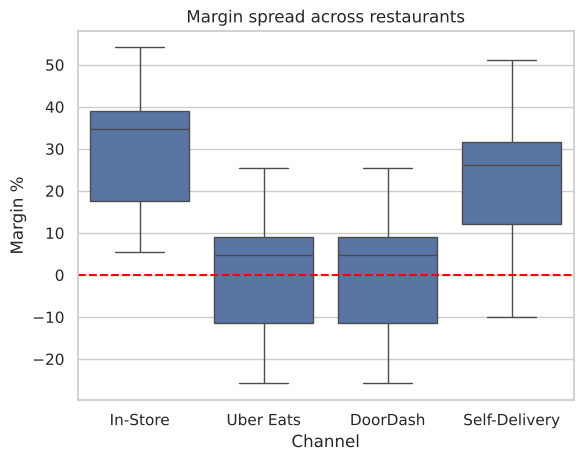

,Average,Volatility,Worst_5pct,Loss-making %
Channel,,,,
In-Store,30.82,11.99,9.33,0.00
Uber Eats,0.79,12.07,-20.91,31.72
DoorDash,0.79,12.07,-20.91,31.72
Self-Delivery,22.60,12.59,-0.31,5.31


In [13]:
sns.boxplot(data=long, x="Channel", y="Margin %", order=order); plt.axhline(0, color="red", ls="--"); plt.title("Margin spread across restaurants"); plt.show()
risk = long.groupby("Channel")["Margin %"].agg(Average="mean", Volatility="std", Worst_5pct=lambda x: x.quantile(.05))
risk["Loss-making %"] = long.groupby("Channel")["Margin %"].apply(lambda x: (x<0).mean()*100)
risk.loc[order]

## 9. Conclusions and recommendations
1. **Volume is not profit.** Aggregators take most orders but make under 1% margin, while In-Store and Self-Delivery make 20%+.
2. **Commission is the cause.** Platforms take almost all profit that exists before commission (see drag index).
3. **Renegotiate.** Roughly a third of restaurants lose money on aggregator orders. Evidence for lowering the commission or negotiating tiers.
4. **Self-delivery pays.** Its cost per order is far below the breakeven cost, so moving orders to self-delivery lifts profit.
5. **Watch fragile groups.** Look at the heatmaps for cuisines/segments with the lowest aggregator margin (high-COGS or high-OPEX models like Full-service).
6. **Use the Streamlit dashboard** to test commission and delivery-cost changes live.